### Week Six - Assignment Data Sets

Here is a dataset that shows a simple 2-node network:  the attendance of 18 Southern Women at 14 social events:

1.   Brief Description. Small “musty” datasets like that from this 1941 study have proven very valuable in testing and comparing new network algorithms.
2.   Dataset.
3. Python code to create dataset: https://networkx.github.io/documentation/stable/auto_examples/algorithms/plot_davis_club.html

What can you infer about the relationships between (1) the women, and (2) the social events?  

Please provide your code and analysis in an Jupyter notebook stored in your GitHub repository.

### Introduction

In this assignment we examine the Davis Southern Women dataset which records the attendance of 18 women at 14 social events. I construct a bipartite network to represent the relationships between women and the events they attended. I then analyse attendance patterns, project the network onto women and events to examine shared attendance, and calculate centrality measures to identify important structural connections. The goal is to understand how the women are connected through their participation and which social events attracted overlapping groups of attendees.

#### Install and import the tools

Here I install and import the necessary libraries for this project.

In [1]:
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from networkx.algorithms import bipartite
from networkx.algorithms.community import greedy_modularity_communities

#### Load Davis Women'sDataset

In this section, I load the Davis Southern Women dataset and examine its basic structure. The network consists of 18 women and 14 social events, represented by 32 nodes and 89 edges. Each edge represents an attendance relationship between a woman and an event.

In [2]:
# Load the Davis Southern Women bipartite network

G = nx.davis_southern_women_graph()

women = G.graph["top"]
events = G.graph["bottom"]

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Women:", len(women))
print("Events:", len(events))

Nodes: 32
Edges: 89
Women: 18
Events: 14


#### Plot of the Original Bipartite Network

The original bipartite network shows the attendance relationships between 18 women and 14 social events in the Davis Southern Club dataset. Women are represented by coral circles, while events are represented by light blue squares, and the edges indicate which women attended each event. The network shows a relatively dense central cluster around events around E6, E7, E8, and E9, suggesting that many women attended the same events. Several women, including Sylvia Avondale, Katherina Rogers, and Verne Sanderson, are connected to multiple events, showing that they took part in several club activities. On the other hand, women such as Flora Price and Olivia Carleton appear further away from the main cluster, suggesting that they had fewer connections with other members. The visualization shows how the women and events are connected within the club. It also provides a starting point for further network analysis, including examining the number of connections, centrality, and shared attendance to identify the most connected women and events.


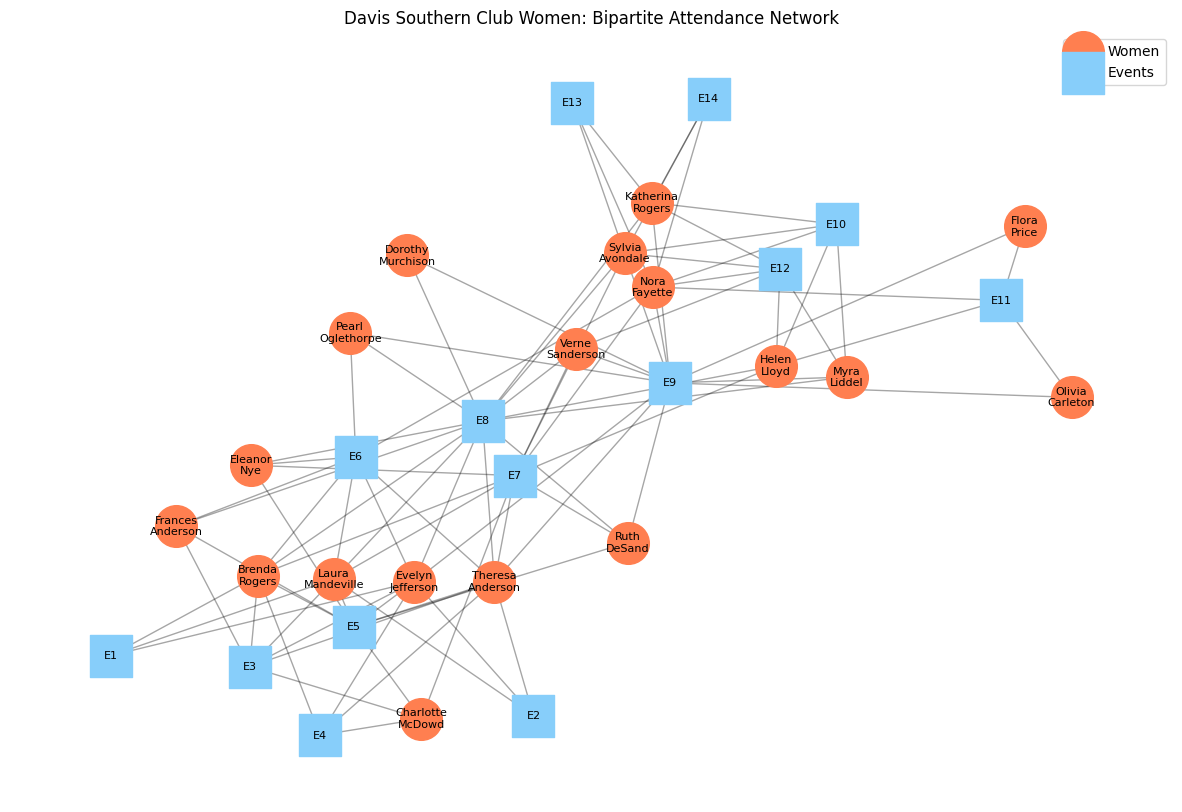

In [3]:
# Original bipartite network
pos = nx.spring_layout(G, seed=648)
plt.figure(figsize=(15, 10))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=women,
    node_color="coral",
    node_size=900,
    label="Women")

nx.draw_networkx_nodes(
    G, pos,
    nodelist=events,
    node_color="lightskyblue",
    node_shape="s",
    node_size=900,
    label="Events")

nx.draw_networkx_edges(G, pos, alpha=0.35)

# Stack women's first and last names vertically
labels = {
    node: node.replace(" ", "\n", 1) if node in women else node
    for node in G.nodes()}

nx.draw_networkx_labels(
    G, pos,
    labels=labels,
    font_size=8,
    verticalalignment="center",
    horizontalalignment="center")

plt.title("Davis Southern Club Women: Bipartite Attendance Network")
plt.legend()
plt.axis("off")
plt.show()

#### Attendance by woman and by event

This section calculates the number of events attended by each woman
and the number of women attending each event. The results provide
a baseline measure of participation and help identify the most
frequent participants and the best-attended events. This gives a general picture of participation and provides a starting point for exploring shared attendance and connections between the women.

The results reveal variation in participation among the women and across social events. Evelyn Jefferson, Theresa Anderson, and Nora Fayette attended the most events, with eight each, followed by Laura Mandeville, Sylvia Avondale, and Brenda Rogers, who attended seven each. Other memberrs like, Dorothy Murchison, Olivia Carleton, and Flora Price attended only two events each. Regarding event attendance, E8 attracted the largest number of participants, with 14 women, followed by E9 with 12 and E7 with 10. The events that attracted the lease number of participants were E1, E1, E13, and E14 with 3. This tells us that participation was unevenly distributed, with some women attending more events and certain events attracting larger groups. Women who attended more events had greater opportunities to interact with other members, while highly attended events provided opportunities for interaction among a wider range of participants. However, attendance frequency alone does not establish the strength of social relationships.

In [4]:
# Attendance by woman and by event

woman_attendance = (
    pd.Series({w: G.degree(w) for w in women})
    .sort_values(ascending=False))

event_attendance = (
    pd.Series({e: G.degree(e) for e in events})
    .sort_values(ascending=False))

display(woman_attendance.to_frame("events_attended"))
display(event_attendance.to_frame("women_attending"))

,events_attended
Evelyn Jefferson,8
Theresa Anderson,8
Nora Fayette,8
Laura Mandeville,7
Sylvia Avondale,7
Brenda Rogers,7
Katherina Rogers,6
Helen Lloyd,5
Charlotte McDowd,4
Frances Anderson,4


,women_attending
E8,14
E9,12
E7,10
E5,8
E6,8
E3,6
E12,6
E10,5
E4,4
E11,4


#### Women's Projection: Co-attendance Strength

In this section, I create a weighted projection of the bipartite network onto the women to examine shared event attendance. Two women are connected if they attended at least one event together, and the weight of each edge represents the number of events they both attended. I calculate each woman's weighted degree or co-attendance strength by summing the weights of all her connections.

The results reveal differences in shared attendance across the network. Theresa Anderson has the highest co-attendance strength, with a score of 57, followed by Evelyn Jefferson with 50, and Sylvia Avondale and Brenda Rogers with 46 each. Laura Mandeville and Nora Fayette also have relatively high scores of 45 and 43, respectively. Other members like Olivia Carleton and Flora Price have the lowest scores, at 14 each. This tells us that Theresa Anderson, Evelyn Jefferson, and several other highly ranked women had substantial overlap in event attendance with other members. However, a high co-attendance strength does not necessarily mean that a woman attended the most events or had the closest friendships. It shows how often her attendance overlapped with that of other women across shared events.

In [5]:
# Women's co-attendance

W = bipartite.weighted_projected_graph(G, women)

# Weight = number of events attended by both women
# Calculate the total number of shared event attendances

woman_strength = (
    pd.Series({
        w: W.degree(w, weight="weight")
        for w in women})
    .sort_values(ascending=False))

display(woman_strength.to_frame("coattendance_strength"))

,coattendance_strength
Theresa Anderson,57
Evelyn Jefferson,50
Sylvia Avondale,46
Brenda Rogers,46
Laura Mandeville,45
Nora Fayette,43
Ruth DeSand,40
Verne Sanderson,38
Katherina Rogers,37
Eleanor Nye,36


#### Strongest Shared-Attendance Relationships Between Women

To identify the strongest shared-attendance relationships, I rank pairs of women by the number of events they attended together. Using the weighted projection of the bipartite network, I sort the edges by weight in descending order. This helps identify which women attended the same social events most often.

The results show that Evelyn Jefferson and Theresa Anderson have the strongest shared-attendance relationship, having attended seven events together. Six shared events are recorded for several other pairs, including Evelyn Jefferson and Laura Mandeville, Evelyn Jefferson and Brenda Rogers, Laura Mandeville and Brenda Rogers, Laura Mandeville and Theresa Anderson, and Theresa Anderson and Brenda Rogers. Katherina Rogers and Sylvia Avondale also share six events. This shows the recurring patterns of shared participation, particularly among Evelyn Jefferson, Theresa Anderson, Laura Mandeville, and Brenda Rogers. The results suggest that these women frequently attended the same social activities, indicating substantial overlap in their participation. However, attending the same events creates opportunities for social interaction but does not necessarily mean that the women were friends or had close personal relationships.

In [6]:
# Identify pairs of women with the most shared events
# Strongest shared-attendance relationships between women

shared_attendance = [
    (u, v, data["weight"])
    for u, v, data in W.edges(data=True)
]

shared_attendance = sorted(
    shared_attendance,
    key=lambda x: x[2],
    reverse=True
)

print("Top 10 pairs of women by shared event attendance:")
for woman1, woman2, weight in shared_attendance[:10]:
    print(f"{woman1} and {woman2}: {weight} shared events")


Top 10 pairs of women by shared event attendance:
Evelyn Jefferson and Theresa Anderson: 7 shared events
Evelyn Jefferson and Laura Mandeville: 6 shared events
Evelyn Jefferson and Brenda Rogers: 6 shared events
Laura Mandeville and Brenda Rogers: 6 shared events
Laura Mandeville and Theresa Anderson: 6 shared events
Theresa Anderson and Brenda Rogers: 6 shared events
Katherina Rogers and Sylvia Avondale: 6 shared events
Sylvia Avondale and Nora Fayette: 6 shared events
Katherina Rogers and Nora Fayette: 5 shared events
Evelyn Jefferson and Frances Anderson: 4 shared events


#### Women's Projected Network

In this section, I plot the projected network of women to examine shared attendance at social events. Each node represents a woman, and an edge connects two women who attended at least one event together. Edge thickness represents the number of events shared by each pair, with thicker edges indicating greater overlap in attendance.

The projected network appears highly interconnected, with numerous connections between members, suggesting substantial overlap in participation across the club's social activities. Women such as Sylvia Avondale, Katherina Rogers, Myra Liddel, and Nora Fayette appear relatively central in the visualization, while Olivia Carleton and Flora Price occupy more outer positions. These patterns suggest differences in how members' attendance overlapped with that of other women. The thicker edges highlight pairs who repeatedly attended the same events, while the broader network structure illustrates how shared participation connects members across the club. The visualization provides a clearer picture of overlapping attendance patterns and the structure of the women's network. However, these connections represent shared event attendance rather than confirmed friendships or direct social influence.

. This suggests that some women shared events with more members than others. The thicker lines show pairs of women who attended more events together, while the overall network shows how shared attendance connects the members. The visualization helps explain how the women's participation overlapped and how they were connected through social events. However, sharing events does not necessarily mean that the women were friends or directly influenced one another.


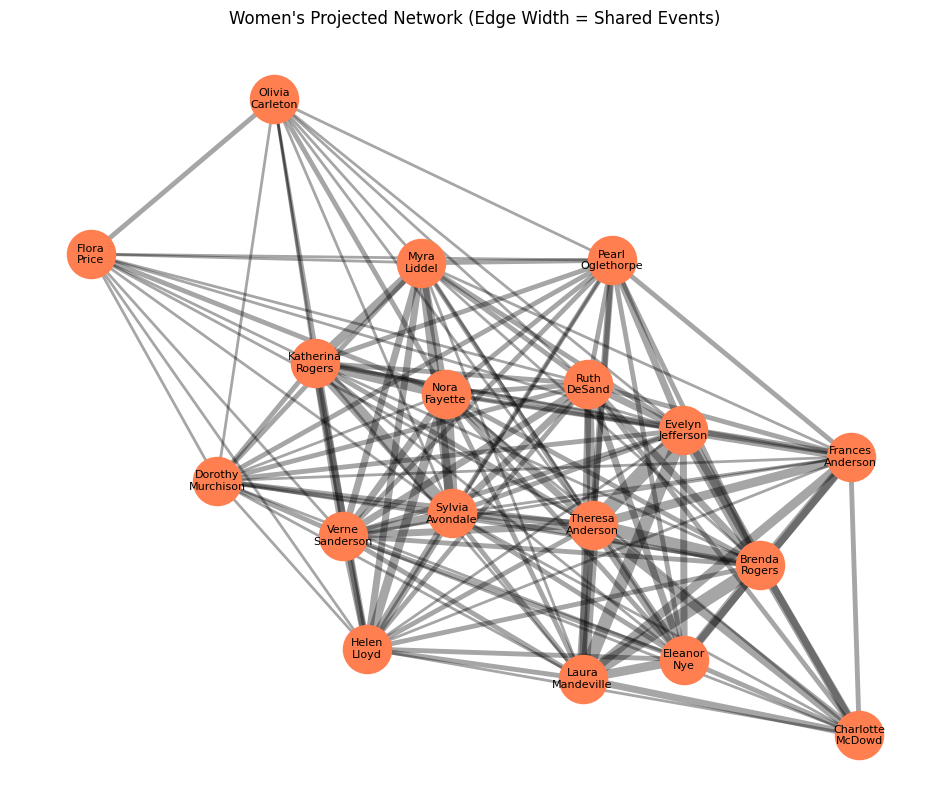

In [7]:
# Women's projected network

plt.figure(figsize=(12, 10))
pos_w = nx.spring_layout(W, seed=648)

edge_widths = [
    0.5 + 1.5 * W[u][v]["weight"]
    for u, v in W.edges()]

nx.draw_networkx_nodes(
    W, pos_w,
    node_color="coral",
    node_size=1200)

nx.draw_networkx_edges(
    W, pos_w,
    width=edge_widths,
    alpha=0.35)

# Stack women's first and last names vertically
labels = {
    node: node.replace(" ", "\n", 1)
    for node in W.nodes()}

nx.draw_networkx_labels(
    W, pos_w,
    labels=labels,
    font_size=8,
    verticalalignment="center",
    horizontalalignment="center")

plt.title("Women's Projected Network (Edge Width = Shared Events)")
plt.axis("off")
plt.show()

#### Event Projection: Co-attendance Strength

In this section, I create a weighted projection of the network onto the events to examine how attendance overlaps across social gatherings. Two events are connected if at least one woman attended both, and the weight of each connection represents the number of women they share. I then calculate each event's co-attendance strength by adding the weights of all its connections and sort the results from highest to lowest. This helps identify which events shared the most attendees with other gatherings.

The results reveal differences in the extent of shared attendance across the social calendar. Event E8 has the highest co-attendance strength, with a score of 59, followed by E7 with 48 and E9 with 46. Events E6 and E5 also have relatively high scores of 41 and 38, respectively. E11 has the lowest score, at 13, indicating less total overlap in attendance with other events. This suggests that E8, E7, and E9 were particularly interconnected with other events through shared attendees, while E11 had comparatively less overlap. Overall, the results show which events shared attendees with other gatherings. However, co-attendance strength measures the total number of shared attendees across an event’s connections, not the total number of women who attended it or how socially important it was.

In [8]:
#  Event
# Two events are connected when they share women.

E = bipartite.weighted_projected_graph(G, events)

event_strength = (
    pd.Series({
        e: E.degree(e, weight="weight")
        for e in events
    })
    .sort_values(ascending=False)
)

display(event_strength.to_frame("coattendance_with_other_events"))

,coattendance_with_other_events
E8,59
E7,48
E9,46
E6,41
E5,38
E3,32
E12,28
E10,25
E4,23
E2,20


#### Strongest shared-attendance relationships between events

In this section, I identify the pairs of events with the greatest overlap in attendance by ranking the connections in the weighted event projection according to their edge weights. Each edge represents two events attended by at least one common woman, while its weight indicates the number of women who attended both events.

The results show that E8 and E9 have the strongest overlap, sharing nine women, followed by E7 and E8, which share eight women. Several other pairs, including E5 and E8, E6 and E8, E3 and E5, E5 and E6, and E5 and E7, also demonstrate substantial overlap, sharing between six and seven women. These findings highlight E5, E6, E7, and E8 as events that frequently attracted overlapping groups of participants. In particular, E8 appears repeatedly among the strongest connections, suggesting that its attendees also participated in several other gatherings. These results show which events attracted similar groups of women and where attendance overlapped across the social calendar. However, shared attendance shows that the events had participants in common, but does not necessarily mean they had the same purpose or social importance.


In [9]:
# Shared attendance between events

E = bipartite.weighted_projected_graph(G, events)

shared_events = sorted(
    E.edges(data=True),
    key=lambda x: x[2]["weight"],
    reverse=True
)

print("Top 10 pairs of events with the most shared attendees:")

for event1, event2, data in shared_events[:10]:
    print(f"{event1} and {event2}: {data['weight']} shared women")

Top 10 pairs of events with the most shared attendees:
E8 and E9: 9 shared women
E7 and E8: 8 shared women
E5 and E8: 7 shared women
E6 and E8: 7 shared women
E3 and E5: 6 shared women
E5 and E7: 6 shared women
E5 and E6: 6 shared women
E3 and E8: 5 shared women
E3 and E6: 5 shared women
E6 and E7: 5 shared women


#### Event Projected Network

In this section, I plot the projected network of events to examine how attendance overlaps across social gatherings. Each node represents an event, and an edge connects two events if they share at least one attendee. The thickness of each edge represents the number of women who attended both events, with thicker edges showing greater overlap. This visualization helps identify events that attracted similar groups of women and highlights which events shared the most attendees.

The event projected network appears relatively interconnected, particularly around events E5, E6, E7, E8, and E9, which form a prominent cluster with substantial overlap in attendance. Event E8 appears particularly well connected to other events, consistent with its highest co-attendance strength of 59. Events E11 and E14 appear more peripheral, suggesting that their attendance patterns overlap less extensively with those of other gatherings. The connections across the network show that women attended multiple events, linking different parts of the social calendar. Overall, the visualization shows how events are connected through shared attendance and highlights differences in how much their attendance overlapped. However, these connections show similarities in attendance rather than necessarily indicating the events' social importance or purpose.


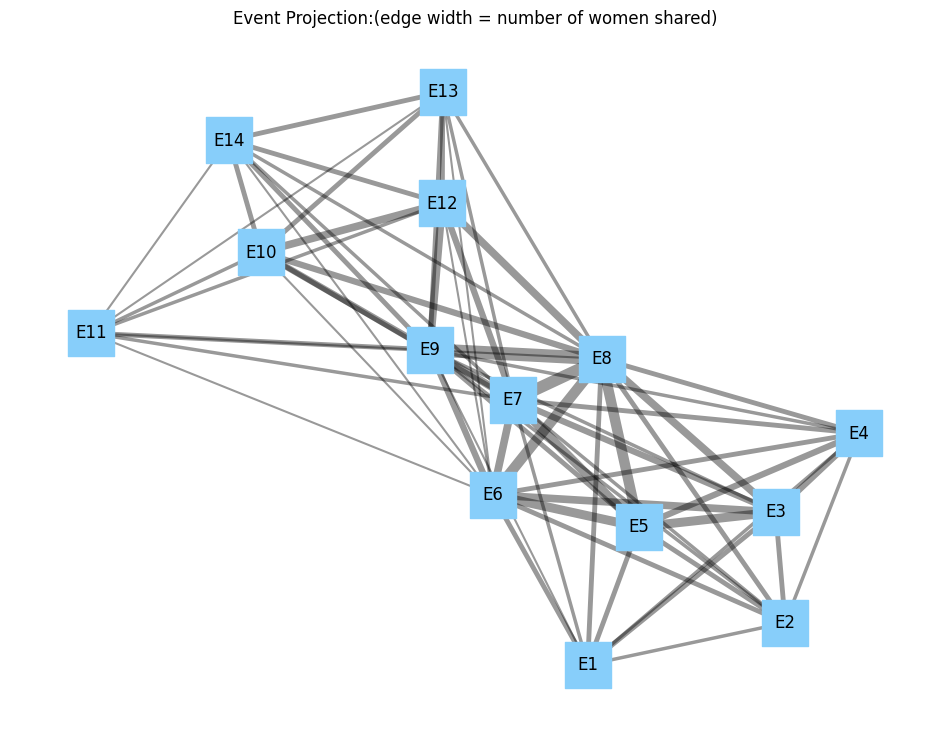

In [10]:
# 10. Event-event projection

plt.figure(figsize=(12, 9))
pos_e = nx.spring_layout(E, seed=648)

edge_widths = [
    0.5 + E[u][v]["weight"]
    for u, v in E.edges()]

nx.draw_networkx_nodes(
    E, pos_e,
    node_color="lightskyblue",
    node_shape="s",
    node_size=1100)

nx.draw_networkx_edges(
    E, pos_e,
    width=edge_widths,
    alpha=0.4)

nx.draw_networkx_labels(E, pos_e)

plt.title("Event Projection:(edge width = number of women shared)")
plt.axis("off")
plt.show()

#### Centrality in the Women's Projection

In this section, I calculate four centrality measures to examine the positions of women within the projected network. Degree centrality, to measures how many other women each woman is connected to, betweenness centrality to identiy women who act as bridges between other members. Closeness centrality to measures how easily a woman can reach other women through the network, and eigenvector centrality to produce scores (higher scores to women connected to other well-connected member). These measures help explain how the women are connected through shared event attendance.

The results show that Evelyn Jefferson, Theresa Anderson, Sylvia Avondale, Verne Sanderson, Ruth DeSand, Nora Fayette, and Helen Lloyd have the highest degree, closeness, and eigenvector centrality scores. Each has a degree and closeness centrality score of 1.000, indicating that they are directly connected to every other woman in the projected network. Their eigenvector centrality score of 0.254 also suggests that they are connected to well-connected members. On the other hand, Charlotte McDowd has the lowest degree centrality (0.647), closeness centrality (0.739), and eigenvector centrality (0.173), meaning she has fewer connections than the other women. Betweenness centrality scores are low across the network, with a maximum of 0.010, suggesting that no woman stands out as a major bridge between other members. The centrality results show that the women are highly interconnected through shared event attendance, although these measures do not necessarily indicate friendship, popularity, or social influence.


In [11]:
# Centrality in the woman projection

centrality = pd.DataFrame({
    "degree": nx.degree_centrality(W),
    "betweenness": nx.betweenness_centrality(W),
    "closeness": nx.closeness_centrality(W),
    "eigenvector": nx.eigenvector_centrality(W, max_iter=1000),
}).sort_values("degree", ascending=False)

display(centrality.round(3))


,degree,betweenness,closeness,eigenvector
Evelyn Jefferson,1.000,0.010,1.000,0.254
Theresa Anderson,1.000,0.010,1.000,0.254
Sylvia Avondale,1.000,0.010,1.000,0.254
Verne Sanderson,1.000,0.010,1.000,0.254
Ruth DeSand,1.000,0.010,1.000,0.254
Nora Fayette,1.000,0.010,1.000,0.254
Helen Lloyd,1.000,0.010,1.000,0.254
Myra Liddel,0.941,0.005,0.944,0.243
Katherina Rogers,0.941,0.005,0.944,0.243
Pearl Oglethorpe,0.941,0.005,0.944,0.243


#### Centrality in the Event Projected Network

In this section, I examine centrality measures in the event projection to understand how individual events are positioned within the network of shared attendance. Degree centrality to measures how many other events each event is connected to, betweenness centrality to identify events that lie on shortest paths between other events, and closeness centrality to measure how efficiently an event can reach other events through network connections. Event attendance is also included to distinguish the number of women attending an event from its structural position in the projected network.

The results show that E8, E9, E7, and E6 have the highest degree centrality scores of 1.000, meaning that each event is connected to every other event in the projection. E8 also has the highest attendance, with 14 women, followed by E9 with 12 and E7 with 10. This suggests that these events had high attendance and shared participants with many other gatherings. Their betweenness centrality scores of 0.08 indicate that they also play a role in connecting events through the shortest paths in the network. The remaining events have lower degree centrality scores of 0.615 and zero betweenness centrality, suggesting that they have fewer connections and do not act as bridges along the shortest paths between other events. The results highlight differences in event attendance and network connections, not that an event was more socially important.

In [12]:
# Centrality in events

event_centrality = pd.DataFrame({
    "attendance": {
        e: G.degree(e)
        for e in events
    },
    "degree_centrality": nx.degree_centrality(E),
    "betweenness": nx.betweenness_centrality(E),
    "closeness": nx.closeness_centrality(E),
}).sort_values("attendance", ascending=False)

display(event_centrality.round(3))

,attendance,degree_centrality,betweenness,closeness
E8,14,1.000,0.08,1.000
E9,12,1.000,0.08,1.000
E7,10,1.000,0.08,1.000
E5,8,0.615,0.00,0.722
E6,8,1.000,0.08,1.000
E3,6,0.615,0.00,0.722
E12,6,0.615,0.00,0.722
E10,5,0.615,0.00,0.722
E4,4,0.615,0.00,0.722
E11,4,0.615,0.00,0.722


## Interpretation and Conclusion

The analysis of the Davis Southern Women dataset shows how bipartite network analysis can be used to explore relationships between women and social events. The original bipartite network provides the clearest representation of the data because it distinguishes between women and events and shows which women attended each gathering. By projecting the network onto women and events separately, I was able to examine their connections in greater detail.

The women's projection shows how members are connected through shared event attendance. Evelyn Jefferson and Theresa Anderson shared the most events, attending seven together, while Theresa Anderson had the highest co-attendance strength, with a score of 57. The centrality analysis also identified several women who were connected to every other woman in the projected network. These findings show that many women shared social activities, although shared attendance does not necessarily mean they were well acquainted or influenced one another.

The event projection shows which gatherings attracted similar groups of women. E8 had the highest attendance, with 14 women, and the highest co-attendance strength, at 59. Events E8 and E9 shared nine attendees, the highest overlap between any pair of events. The connections among E5, E6, E7, E8, and E9 also show that these gatherings shared many participants.

The women's and event projections provide different but complementary views of the club's social structure. The women's projection highlights shared participation between members, while the event projection shows which gatherings attracted overlapping groups of attendees. Although centrality and co-attendance measures help explain these patterns, they do not directly establish friendship, popularity, or social influence. The original bipartite network therefore remains important because it preserves the direct relationships between women and the events they attended.
